# EDA – AI-Powered Chatbot for University Student Support (Project 30)
**HCLTech Career Shaper Programme · III Year Industry Project · 2025-26**

This notebook explores `dataset.csv` (500 chatbot sessions), validates data quality, creates the cleaned/pre-processed dataset and records insights that drive the chatbot's escalation design.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, pathlib
from scipy import stats
sns.set_theme(style='whitegrid', context='notebook'); plt.rcParams['figure.dpi']=110
ROOT = pathlib.Path('..'); FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
df = pd.read_csv(ROOT/'data'/'dataset_raw.csv'); dd = pd.read_csv(ROOT/'data'/'data_dictionary_original.csv')
print(df.shape); df.head()

(500, 6)


,session_id,user_query_type,intent,confidence_score,escalated,user_rating
0,S0001,query_type_5,grievance,0.682,0,5
1,S0002,query_type_4,admissions,0.802,0,5
2,S0003,query_type_3,hostel,0.896,0,3
3,S0004,query_type_5,exams,0.649,0,3
4,S0005,query_type_2,hostel,0.661,0,1


## 1. Data quality checks

In [2]:
checks = {'rows':len(df),'columns':df.shape[1],'missing values':int(df.isna().sum().sum()),'duplicate rows':int(df.duplicated().sum()),
 'duplicate session_id':int(df.session_id.duplicated().sum()),
 'confidence outside [0,1]':int((~df.confidence_score.between(0,1)).sum()),'escalated not in {0,1}':int((~df.escalated.isin([0,1])).sum()),
 'rating not in 1..5':int((~df.user_rating.between(1,5)).sum())}
display(pd.Series(checks, name='value').to_frame())
display(df.describe(include='all').T)

,value
rows,500
columns,6
missing values,0
duplicate rows,0
duplicate session_id,0
"confidence outside [0,1]",0
"escalated not in {0,1}",0
rating not in 1..5,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,500,500,S0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_query_type,500,5,query_type_4,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
intent,500,7,admissions,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
confidence_score,500.0,NaN,NaN,NaN,0.79689,0.117885,0.602,0.69075,0.7905,0.90125,0.999
escalated,500.0,NaN,NaN,NaN,0.078,0.26844,0.0,0.0,0.0,0.0,1.0
user_rating,500.0,NaN,NaN,NaN,3.08,1.421845,1.0,2.0,3.0,4.0,5.0


**Finding:** the file is already clean – no nulls, duplicates or out-of-range values. Pre-processing therefore focuses on type conversion, validation and *feature engineering*.

## 2. Pre-processing & feature engineering

In [3]:
clean = df.copy()
clean['session_id'] = clean.session_id.str.strip().str.upper()
for c in ['user_query_type','intent']: clean[c] = clean[c].str.strip().str.lower().astype('category')
clean['escalated'] = clean.escalated.astype('int8'); clean['user_rating'] = clean.user_rating.astype('int8')
clean['confidence_band'] = pd.cut(clean.confidence_score, [0,0.7,0.8,0.9,1.0], labels=['low (<0.70)','medium (0.70-0.79)','high (0.80-0.89)','very high (>=0.90)'], right=False)
clean['low_confidence'] = (clean.confidence_score < 0.70).astype('int8')
clean['satisfied'] = (clean.user_rating >= 4).astype('int8')
clean['dissatisfied'] = (clean.user_rating <= 2).astype('int8')
clean['query_type_num'] = clean.user_query_type.str.extract(r'(\d)').astype('int8')
clean.to_csv(ROOT/'data'/'dataset.csv', index=False)
print('saved', clean.shape); clean.head()

saved (500, 11)


,session_id,user_query_type,intent,confidence_score,escalated,user_rating,confidence_band,low_confidence,satisfied,dissatisfied,query_type_num
0,S0001,query_type_5,grievance,0.682,0,5,low (<0.70),1,1,0,5
1,S0002,query_type_4,admissions,0.802,0,5,high (0.80-0.89),0,1,0,4
2,S0003,query_type_3,hostel,0.896,0,3,high (0.80-0.89),0,0,0,3
3,S0004,query_type_5,exams,0.649,0,3,low (<0.70),1,0,0,5
4,S0005,query_type_2,hostel,0.661,0,1,low (<0.70),1,0,1,2


## 3. Visualisations

### 3.1 Query volume by intent

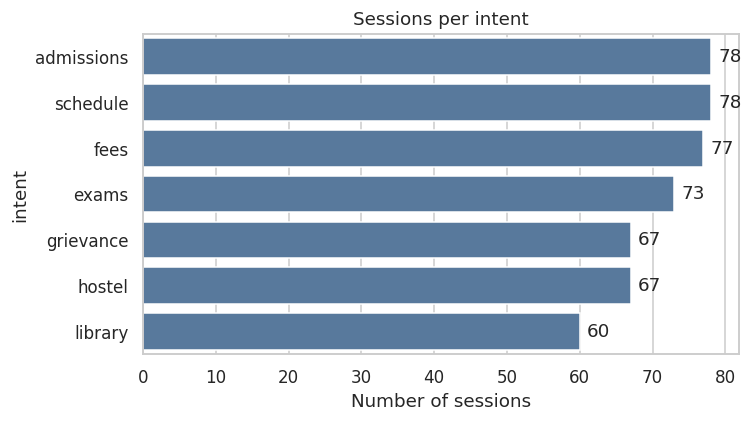

In [4]:
order = clean.intent.value_counts().index
fig, ax = plt.subplots(figsize=(7,4)); sns.countplot(data=clean, y='intent', order=order, color='#4C78A8', ax=ax)
for p in ax.patches: ax.annotate(int(p.get_width()), (p.get_width()+1, p.get_y()+p.get_height()/2), va='center')
ax.set_title('Sessions per intent'); ax.set_xlabel('Number of sessions'); plt.tight_layout(); plt.savefig(FIG/'fig_eda_intent_volume.png', dpi=160); plt.show()

Traffic is spread fairly evenly: admissions and schedule are the most frequent topics (78 each) and library the least (60) – no single intent dominates, so the classifier must be good across all topics.

### 3.2 Distribution of intent-classification confidence

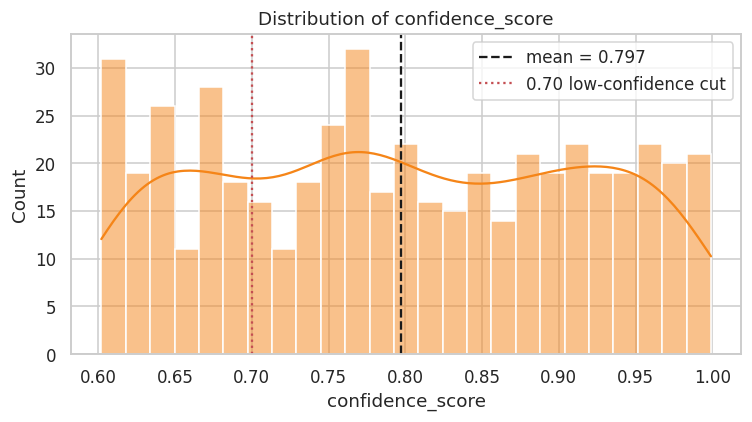

share below 0.70: 0.268 | skew: 0.014


In [5]:
fig, ax = plt.subplots(figsize=(7,4)); sns.histplot(clean.confidence_score, bins=25, kde=True, color='#F58518', ax=ax)
ax.axvline(clean.confidence_score.mean(), ls='--', c='k', label=f'mean = {clean.confidence_score.mean():.3f}'); ax.axvline(0.7, ls=':', c='r', label='0.70 low-confidence cut')
ax.set_title('Distribution of confidence_score'); ax.legend(); plt.tight_layout(); plt.savefig(FIG/'fig_eda_confidence_hist.png', dpi=160); plt.show()
print('share below 0.70:', round(clean.low_confidence.mean(),3), '| skew:', round(stats.skew(clean.confidence_score),3))

Confidence is spread almost uniformly between 0.60 and 1.00 (mean 0.797). About 27 % of sessions (26.8 %) are below 0.70 – these are the turns where a safety-net (rephrase / human hand-over) matters.

### 3.3 Escalation rate by intent

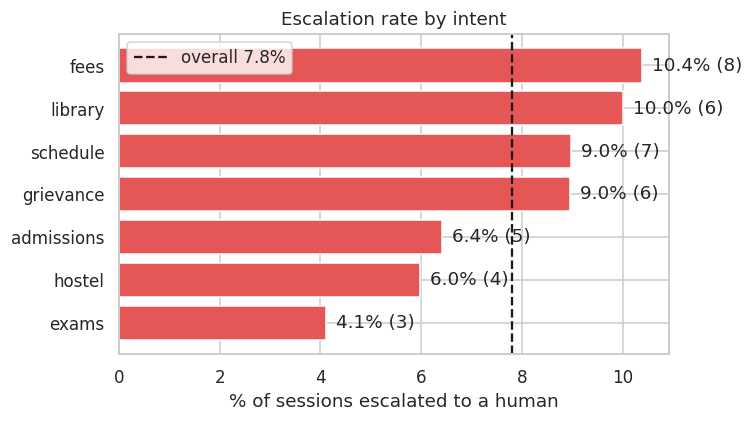

chi-square intent vs escalated: chi2=3.30, p=0.770


In [6]:
g = clean.groupby('intent', observed=True).escalated.agg(['mean','sum','count']).sort_values('mean', ascending=False)
fig, ax = plt.subplots(figsize=(7,4)); ax.barh(g.index, g['mean']*100, color='#E45756'); ax.invert_yaxis()
ax.axvline(clean.escalated.mean()*100, ls='--', c='k', label=f'overall {clean.escalated.mean()*100:.1f}%')
for i,(m,s) in enumerate(zip(g['mean'], g['sum'])): ax.text(m*100+0.2, i, f'{m*100:.1f}% ({s})', va='center')
ax.set_xlabel('% of sessions escalated to a human'); ax.set_title('Escalation rate by intent'); ax.legend(); plt.tight_layout(); plt.savefig(FIG/'fig_eda_escalation_by_intent.png', dpi=160); plt.show()
ct = pd.crosstab(clean.intent, clean.escalated); chi2,p,_,_ = stats.chi2_contingency(ct); print(f'chi-square intent vs escalated: chi2={chi2:.2f}, p={p:.3f}')

Overall only **7.8 %** (39/500) of sessions were escalated. Fees and library show the highest rates (≈10 %) and exams the lowest (4 %), but the chi-square test is **not significant** – differences between intents are within random variation.

### 3.4 Satisfaction ratings

/tmp/ipykernel_195/1643749913.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  sns.barplot(data=clean, x='escalated', y='user_rating', color='#72B7B2', errorbar=('ci',95), ax=axs[1]); axs[1].set_xticklabels(['Handled by bot (0)','Escalated (1)']); axs[1].set_title('Mean rating: bot vs escalated (95% CI)'); axs[1].set_xlabel('')


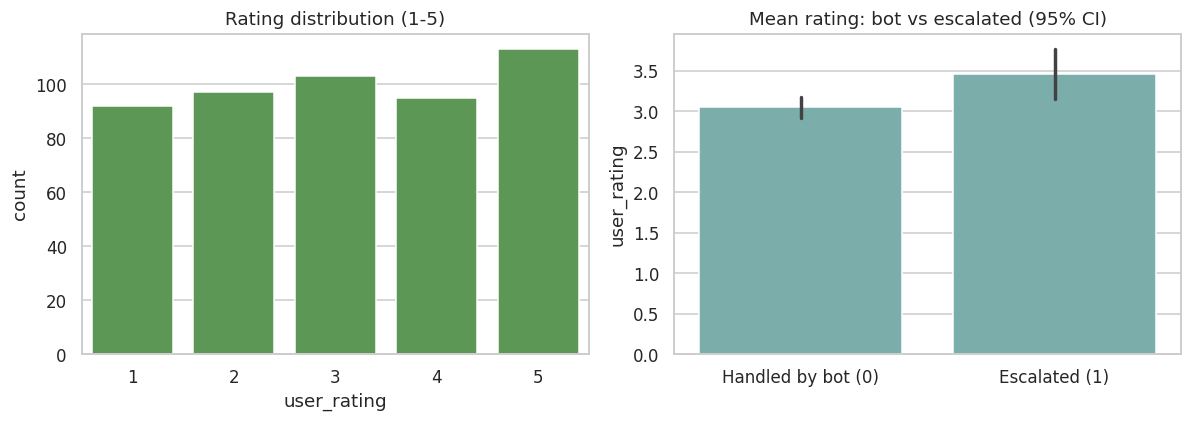

mean rating bot / escalated: 3.05 3.46
MannwhitneyuResult(statistic=np.float64(7549.5), pvalue=np.float64(0.08981856468083985))
CSAT (rating>=4): 41.6 %   Dissatisfied (<=2): 37.8 %


In [7]:
fig, axs = plt.subplots(1,2, figsize=(11,4))
sns.countplot(data=clean, x='user_rating', color='#54A24B', ax=axs[0]); axs[0].set_title('Rating distribution (1-5)')
sns.barplot(data=clean, x='escalated', y='user_rating', color='#72B7B2', errorbar=('ci',95), ax=axs[1]); axs[1].set_xticklabels(['Handled by bot (0)','Escalated (1)']); axs[1].set_title('Mean rating: bot vs escalated (95% CI)'); axs[1].set_xlabel('')
plt.tight_layout(); plt.savefig(FIG/'fig_eda_ratings.png', dpi=160); plt.show()
a = clean[clean.escalated==0].user_rating; b = clean[clean.escalated==1].user_rating
print('mean rating bot / escalated:', round(a.mean(),2), round(b.mean(),2)); print(stats.mannwhitneyu(a,b))
print('CSAT (rating>=4):', round(clean.satisfied.mean()*100,1),'%   Dissatisfied (<=2):', round(clean.dissatisfied.mean()*100,1),'%')

Ratings are almost flat (≈18–23 % per star; mean 3.08, CSAT ≈ 41.6 %). Escalated sessions are rated slightly **higher** (3.46 vs 3.05) – consistent with the idea that reaching a human does not hurt satisfaction – but with only 39 escalations the difference is **not statistically significant** (Mann-Whitney p = 0.09).

### 3.5 Confidence vs. escalation and rating

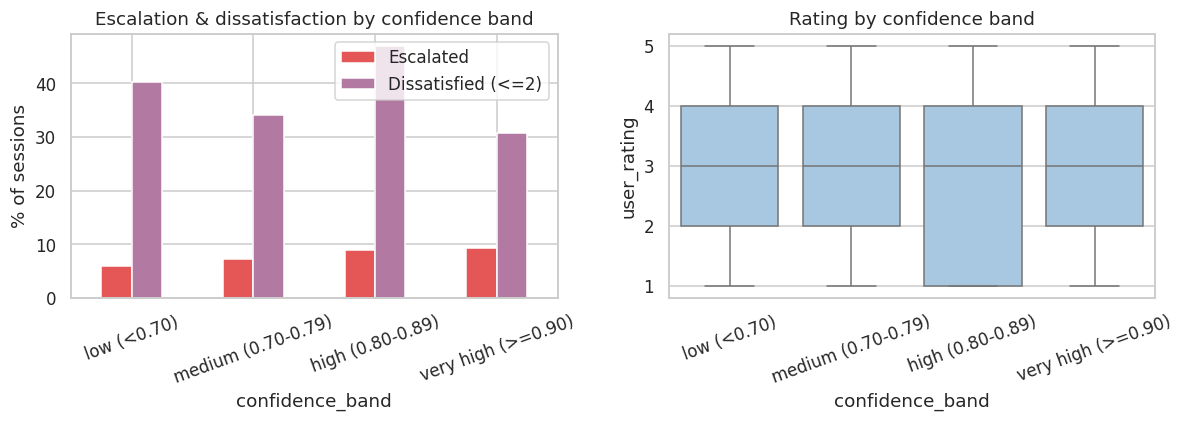

                    escalated  dissatisfied
confidence_band                            
low (<0.70)               6.0          40.3
medium (0.70-0.79)        7.3          34.1
high (0.80-0.89)          8.8          46.9
very high (>=0.90)        9.2          30.8
Spearman conf~escalated SignificanceResult(statistic=np.float64(0.04340324261135513), pvalue=np.float64(0.33276807556017063))
Spearman conf~rating SignificanceResult(statistic=np.float64(0.034047534705379745), pvalue=np.float64(0.447469339590679))


In [8]:
fig, axs = plt.subplots(1,2, figsize=(11,4))
r = clean.groupby('confidence_band', observed=True)[['escalated','dissatisfied']].mean()*100
r.plot(kind='bar', ax=axs[0], color=['#E45756','#B279A2'], rot=20); axs[0].set_ylabel('% of sessions'); axs[0].set_title('Escalation & dissatisfaction by confidence band'); axs[0].legend(['Escalated','Dissatisfied (<=2)'])
sns.boxplot(data=clean, x='confidence_band', y='user_rating', color='#9ecae9', ax=axs[1]); axs[1].set_title('Rating by confidence band'); axs[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(FIG/'fig_eda_confidence_vs_outcome.png', dpi=160); plt.show()
print(r.round(1))
rho1 = stats.spearmanr(clean.confidence_score, clean.escalated); rho2 = stats.spearmanr(clean.confidence_score, clean.user_rating)
print('Spearman conf~escalated', rho1); print('Spearman conf~rating', rho2)

**Key insight:** confidence is essentially *uncorrelated* with both escalation (ρ ≈ 0.04) and rating (ρ ≈ 0.03). In this log, low-confidence answers were **not** escalated more often (6.0 % in the lowest band vs 9.2 % in the highest) – so a pure confidence-threshold policy would not reproduce the historical behaviour. This motivated a **multi-signal escalation policy** (explicit request, sentiment, safety keywords, repeated confusion) instead of confidence alone.

### 3.6 Correlation heat-map and query-type view

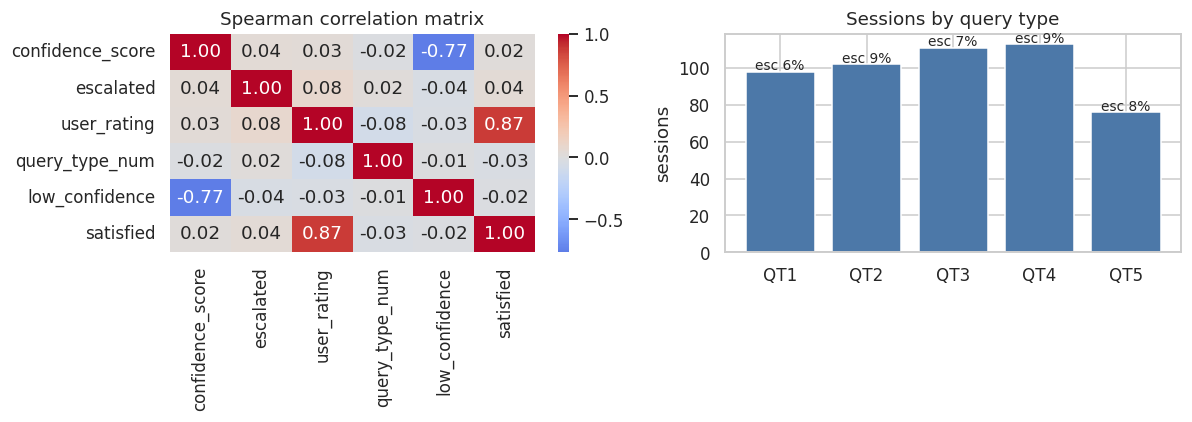

,sessions,esc,rating
user_query_type,,,
query_type_1,98,0.061,3.316
query_type_2,102,0.088,3.088
query_type_3,111,0.072,3.117
query_type_4,113,0.088,2.858
query_type_5,76,0.079,3.039


In [9]:
fig, axs = plt.subplots(1,2, figsize=(11,4))
sns.heatmap(clean[['confidence_score','escalated','user_rating','query_type_num','low_confidence','satisfied']].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axs[0]); axs[0].set_title('Spearman correlation matrix')
q = clean.groupby('user_query_type', observed=True).agg(sessions=('session_id','count'), esc=('escalated','mean'), rating=('user_rating','mean'))
axs[1].bar(q.index.str.replace('query_type_','QT'), q.sessions, color='#4C78A8'); axs[1].set_title('Sessions by query type'); axs[1].set_ylabel('sessions')
for i,(s,e) in enumerate(zip(q.sessions,q.esc)): axs[1].text(i, s+1, f'esc {e*100:.0f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig(FIG/'fig_eda_correlation.png', dpi=160); plt.show(); q.round(3)

## 4. Summary of findings & implications for the chatbot
| # | Finding | Implication |
|---|---|---|
| 1 | Data is complete & valid (500 rows, 0 nulls/duplicates) | Only feature engineering needed |
| 2 | 7 intents, fairly balanced (60–78 sessions each) | Train a 7-class classifier; no re-sampling needed |
| 3 | Mean confidence 0.797; ~27 % below 0.70 | Use a confidence floor and ask the student to rephrase |
| 4 | Escalation rate 7.8 %; no significant difference between intents | Escalation must be driven by *content signals*, not topic |
| 5 | Confidence ≈ uncorrelated with escalation/rating | Add sentiment, explicit-request and safety rules to the policy |
| 6 | CSAT (rating ≥ 4) ≈ 41.6 %; ratings nearly uniform | Target: improve CSAT via better answers + visible human hand-over |

**Caveat:** the weak relationships between all variables suggest `dataset.csv` is synthetic (generated from the programme's dataset-generation prompt). Conclusions about real-world behaviour should therefore be treated as illustrative; the dataset has no raw text, so a separate labelled utterance corpus and FAQ base were created to train the NLP components (see report §4.3).

## 5. Export updated data dictionary

In [10]:
new = pd.DataFrame([
 ['confidence_band','categorical string','medium (0.70-0.79)','very high (>=0.90)','low (<0.70)','No','Engineered: confidence_score binned into 4 bands.'],
 ['low_confidence','int8 (binary)','0','1','0','No','Engineered: 1 if confidence_score < 0.70 (bot unsure), else 0.'],
 ['satisfied','int8 (binary)','1','0','1','No','Engineered: 1 if user_rating >= 4 (CSAT numerator).'],
 ['dissatisfied','int8 (binary)','0','1','0','No','Engineered: 1 if user_rating <= 2.'],
 ['query_type_num','int8','5','4','3','No','Engineered: numeric tier (1-5) extracted from user_query_type.']], columns=dd.columns)
full = pd.concat([dd, new], ignore_index=True); full.to_csv(ROOT/'data'/'data_dictionary.csv', index=False)
print(full.shape); full[['column_name','data_type','description']]

(11, 7)


,column_name,data_type,description
0,session_id,string,Unique anonymous session identifier generated ...
1,user_query_type,categorical string,Categorical taxonomy tier representing query s...
2,intent,categorical string,Primary student domain topic predicted or logg...
3,confidence_score,float64,Estimated model confidence score for intent cl...
4,escalated,int64 (binary),Binary indicator of human agent escalation (0 ...
5,user_rating,int64 (ordinal),Student post-interaction satisfaction score re...
6,confidence_band,categorical string,Engineered: confidence_score binned into 4 bands.
7,low_confidence,int8 (binary),Engineered: 1 if confidence_score < 0.70 (bot ...
8,satisfied,int8 (binary),Engineered: 1 if user_rating >= 4 (CSAT numera...
9,dissatisfied,int8 (binary),Engineered: 1 if user_rating <= 2.
